In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [24]:
df = pd.read_csv('data/ecommerce_dataset.csv')

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      1000 non-null   str    
 1   external_id     1000 non-null   int64  
 2   title           1000 non-null   str    
 3   brand           1000 non-null   str    
 4   category        1000 non-null   str    
 5   subcategory     0 non-null      float64
 6   url             1000 non-null   str    
 7   source          1000 non-null   str    
 8   price_current   1000 non-null   float64
 9   price_original  284 non-null    float64
 10  currency        1000 non-null   str    
 11  discount_pct    284 non-null    float64
 12  has_discount    1000 non-null   bool   
 13  rating_score    796 non-null    float64
 14  reviews_count   1000 non-null   int64  
 15  availability    1000 non-null   str    
 16  description     1000 non-null   str    
 17  images_count    1000 non-null   int64  
 18  

In [30]:
df.head()

,title,brand,category,source,price_current,price_original,currency,discount_pct,has_discount,rating_score,reviews_count,availability,description
0,Huawei Tablet Pro,Huawei,Electronics,amazon,1487.49,NaN,USD,NaN,False,4.8,177,in_stock,Crafted with attention to detail and backed by...
1,Adidas Portable Hoodie Plus,Adidas,Fashion,amazon,1125.26,1575.36,USD,28.6,True,3.7,665,out_of_stock,A versatile product suitable for a wide range ...
2,Calvin Klein Sneakers Pro,Calvin,Fashion,amazon,1357.13,NaN,USD,NaN,False,3.9,379,out_of_stock,Thoughtfully designed to deliver value without...
3,Nestle Lightweight Dried Fruits Pro,Nestle,Food,amazon,1553.58,1724.47,USD,9.9,True,4.1,4,limited,A trusted choice for professionals and enthusi...
4,Braun Portable Vacuum Cleaner 2024,Braun,Home,amazon,509.81,NaN,USD,NaN,False,4.5,88,in_stock,Combining modern aesthetics with functional en...


### Data understanding

In [12]:
df['product_id'].unique()
df['product_id'].nunique()

1000

In [16]:
df['images_count'].unique()
#df['images_count'].nunique()

array([1])

In [14]:
df['source'].value_counts()

source
amazon        200
noon          200
aliexpress    200
jumia         200
ebay          200
Name: count, dtype: int64

In [18]:
df[['source','category','tags']].head(15)

,source,category,tags
0,amazon,Electronics,amazon|electronics
1,amazon,Fashion,amazon|fashion
2,amazon,Fashion,amazon|fashion
3,amazon,Food,amazon|food
4,amazon,Home,amazon|home
5,amazon,Beauty,amazon|beauty
6,amazon,Automotive,amazon|automotive
7,amazon,Sports,amazon|sports
8,amazon,Garden,amazon|garden
9,amazon,Garden,amazon|garden


### Remving unnecessary columns

In [28]:
#df = df.drop(columns=['product_id','external_id','subcategory', 'url','images_count', 'first_image', 'tags' ,'scraped_at'])
df.drop(columns=['product_id','external_id','subcategory', 'url','images_count', 'first_image', 'tags' ,'scraped_at'], inplace=True)

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   title           1000 non-null   str    
 1   brand           1000 non-null   str    
 2   category        1000 non-null   str    
 3   source          1000 non-null   str    
 4   price_current   1000 non-null   float64
 5   price_original  284 non-null    float64
 6   currency        1000 non-null   str    
 7   discount_pct    284 non-null    float64
 8   has_discount    1000 non-null   bool   
 9   rating_score    796 non-null    float64
 10  reviews_count   1000 non-null   int64  
 11  availability    1000 non-null   str    
 12  description     1000 non-null   str    
dtypes: bool(1), float64(4), int64(1), str(7)
memory usage: 94.9 KB


### Visualization

In [49]:
print(df['reviews_count'].max())

2316


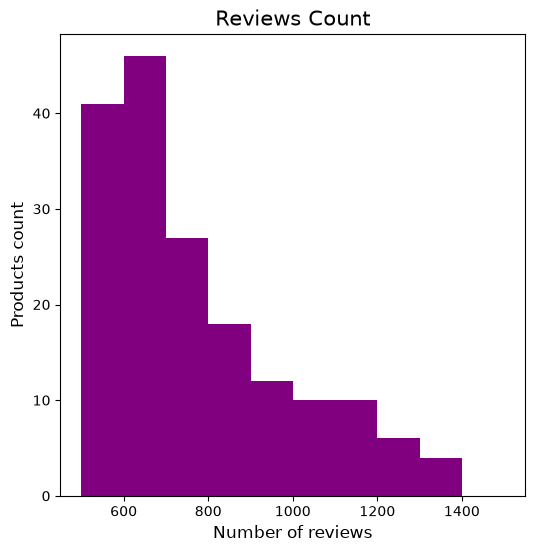

In [50]:
plt.figure(figsize=[6,6])

plt.hist(df['reviews_count'], bins=10, color='purple', orientation='vertical', range=(500,1500))
plt.title("Reviews Count", fontsize= 15)
plt.xlabel("Number of reviews", fontsize= 12)
plt.ylabel("Products count", fontsize= 12)

plt.show()

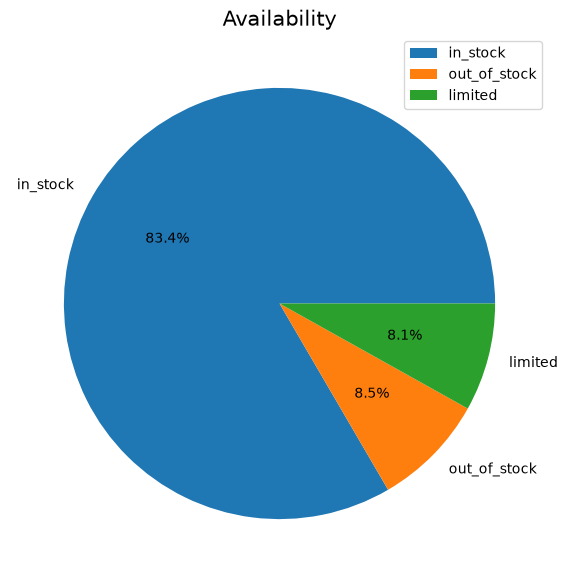

In [58]:

availability = df['availability'].value_counts()

plt.figure(figsize=[7,7])

plt.pie(availability, labels=availability.index, autopct='%1.1f%%')
plt.title("Availability", fontsize= 15)
plt.legend()

plt.show()

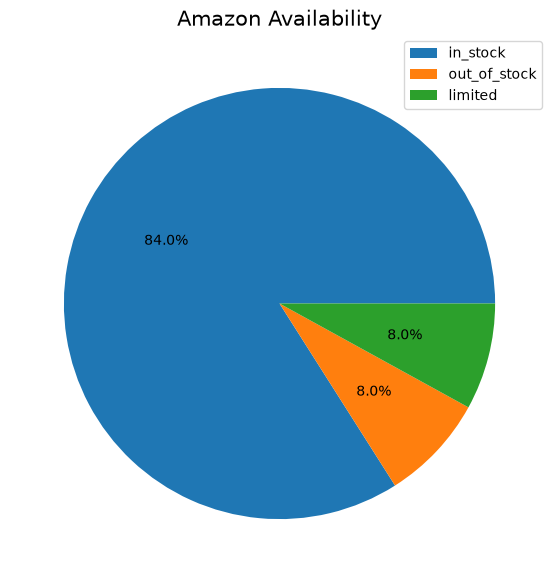

In [60]:
amazon_availability = df[df['source'] == "amazon"]['availability'].value_counts()

plt.figure(figsize=[7,7])

plt.pie(amazon_availability, autopct='%1.1f%%')
plt.title("Amazon Availability", fontsize= 15)
plt.legend(amazon_availability.index)

plt.show()

In [62]:
for source in df['source'].unique():
    print(f"Number of out of stock products in {source} is {df[ (df['source'] == source) &  (df['availability'] == "out_of_stock")]['availability'].count()}")

Number of out of stock products in amazon is 16
Number of out of stock products in noon is 15
Number of out of stock products in aliexpress is 20
Number of out of stock products in jumia is 12
Number of out of stock products in ebay is 22


[np.int64(16), np.int64(15), np.int64(20), np.int64(12), np.int64(22)]


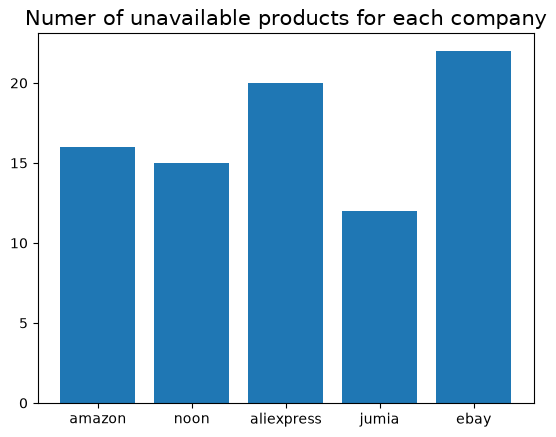

In [64]:
unavailable_products = df[df['availability'] == "out_of_stock"]

company_products = []

for source in unavailable_products['source'].unique():
    out_of_stock_products = unavailable_products[unavailable_products['source'] == source]['availability'].count()
    company_products.append(out_of_stock_products)

print(company_products)

plt.bar(unavailable_products['source'].unique(), company_products)
plt.title("Numer of unavailable products for each company", fontsize= 15)

plt.show()
